## Experiment

In [1]:
import os
for k,v in os.environ.items():
    if k.startswith("QUANTDATA_"):
        print(f"{k}={v}")
        

QUANTDATA_EXPERIMENTS=/media/storage/quantdata/experiments
QUANTDATA_PROCESSING_DATA=/media/storage/quantdata/processing
QUANTDATA_RAW_DATA=/mnt/aae/quantdata
QUANTDATA_TRAINING_DATA=/media/storage/quantdata/training


In [2]:

%load_ext autoreload
%autoreload 1

%aimport quantdata.dysanos.grid.torch_market
%aimport quantdata.dysanos.grid.torch_pricer
%aimport quantdata.dysanos.grid.torch_model
%aimport quantdata.dysanos.grid.torch_gfx 
%aimport quantdata.dysanos.grid.torch_train 
%aimport quantdata.dysanos.grid.torch_simulator
%aimport quantdata.dysanos.grid.torch_universe
%aimport quantdata.dysanos.grid.torch_det_measure_change
%aimport quantdata.dysanos.grid.torch_all
%aimport quantdata.dysanos.grid.torch_drift_change
%aimport quantdata.dysanos.grid.torch_drift_changeV2

from quantdata.dysanos.grid.torch_all import run_experiment_tight, DysanosExperiment, PrettyObject
import gc
gc.collect()

experiment_config = DysanosExperiment(num_samples=100_000)

ex = run_experiment_tight(
    experiment_config,
    plot_sampler=True,
    plot_det_measure_change=True)
ex = PrettyObject(ex)

print("*** READY ***")

*** READY ***


0.0 GiB allocated
0.0 GiB reserved
00: Training drn-pf-std_cost-powerexp-batch version 0.1 group 'dysanosV2' for 200000 epochs.
00: Using batches of 10000 samples with learning rate 0.001 and weight decay 0.
00: Instantiating drn-pf-std_cost-powerexp-batch version 0.1 on Env(prec=32,device=cuda,debug=False)... done; this took 0.11s.
00: Using recovery checkpoint '/home/hans/.dysanos_dhx/dysanosV2/drn-pf-std_cost-powerexp-batch 5eb9629d.pt'.
00: Copied 7 arrays with a total size 2070.62MB to Env(prec=32,device=cuda,debug=False). This took 0.31s.                          
00: Initial training loss is 2.842 and validation loss 3.137. This took 0.48s.
00: Compiling drn-pf-std_cost-powerexp-batch@dysanosV2 0.1 for cuda: training... valuation... validation... done; this took 12s.


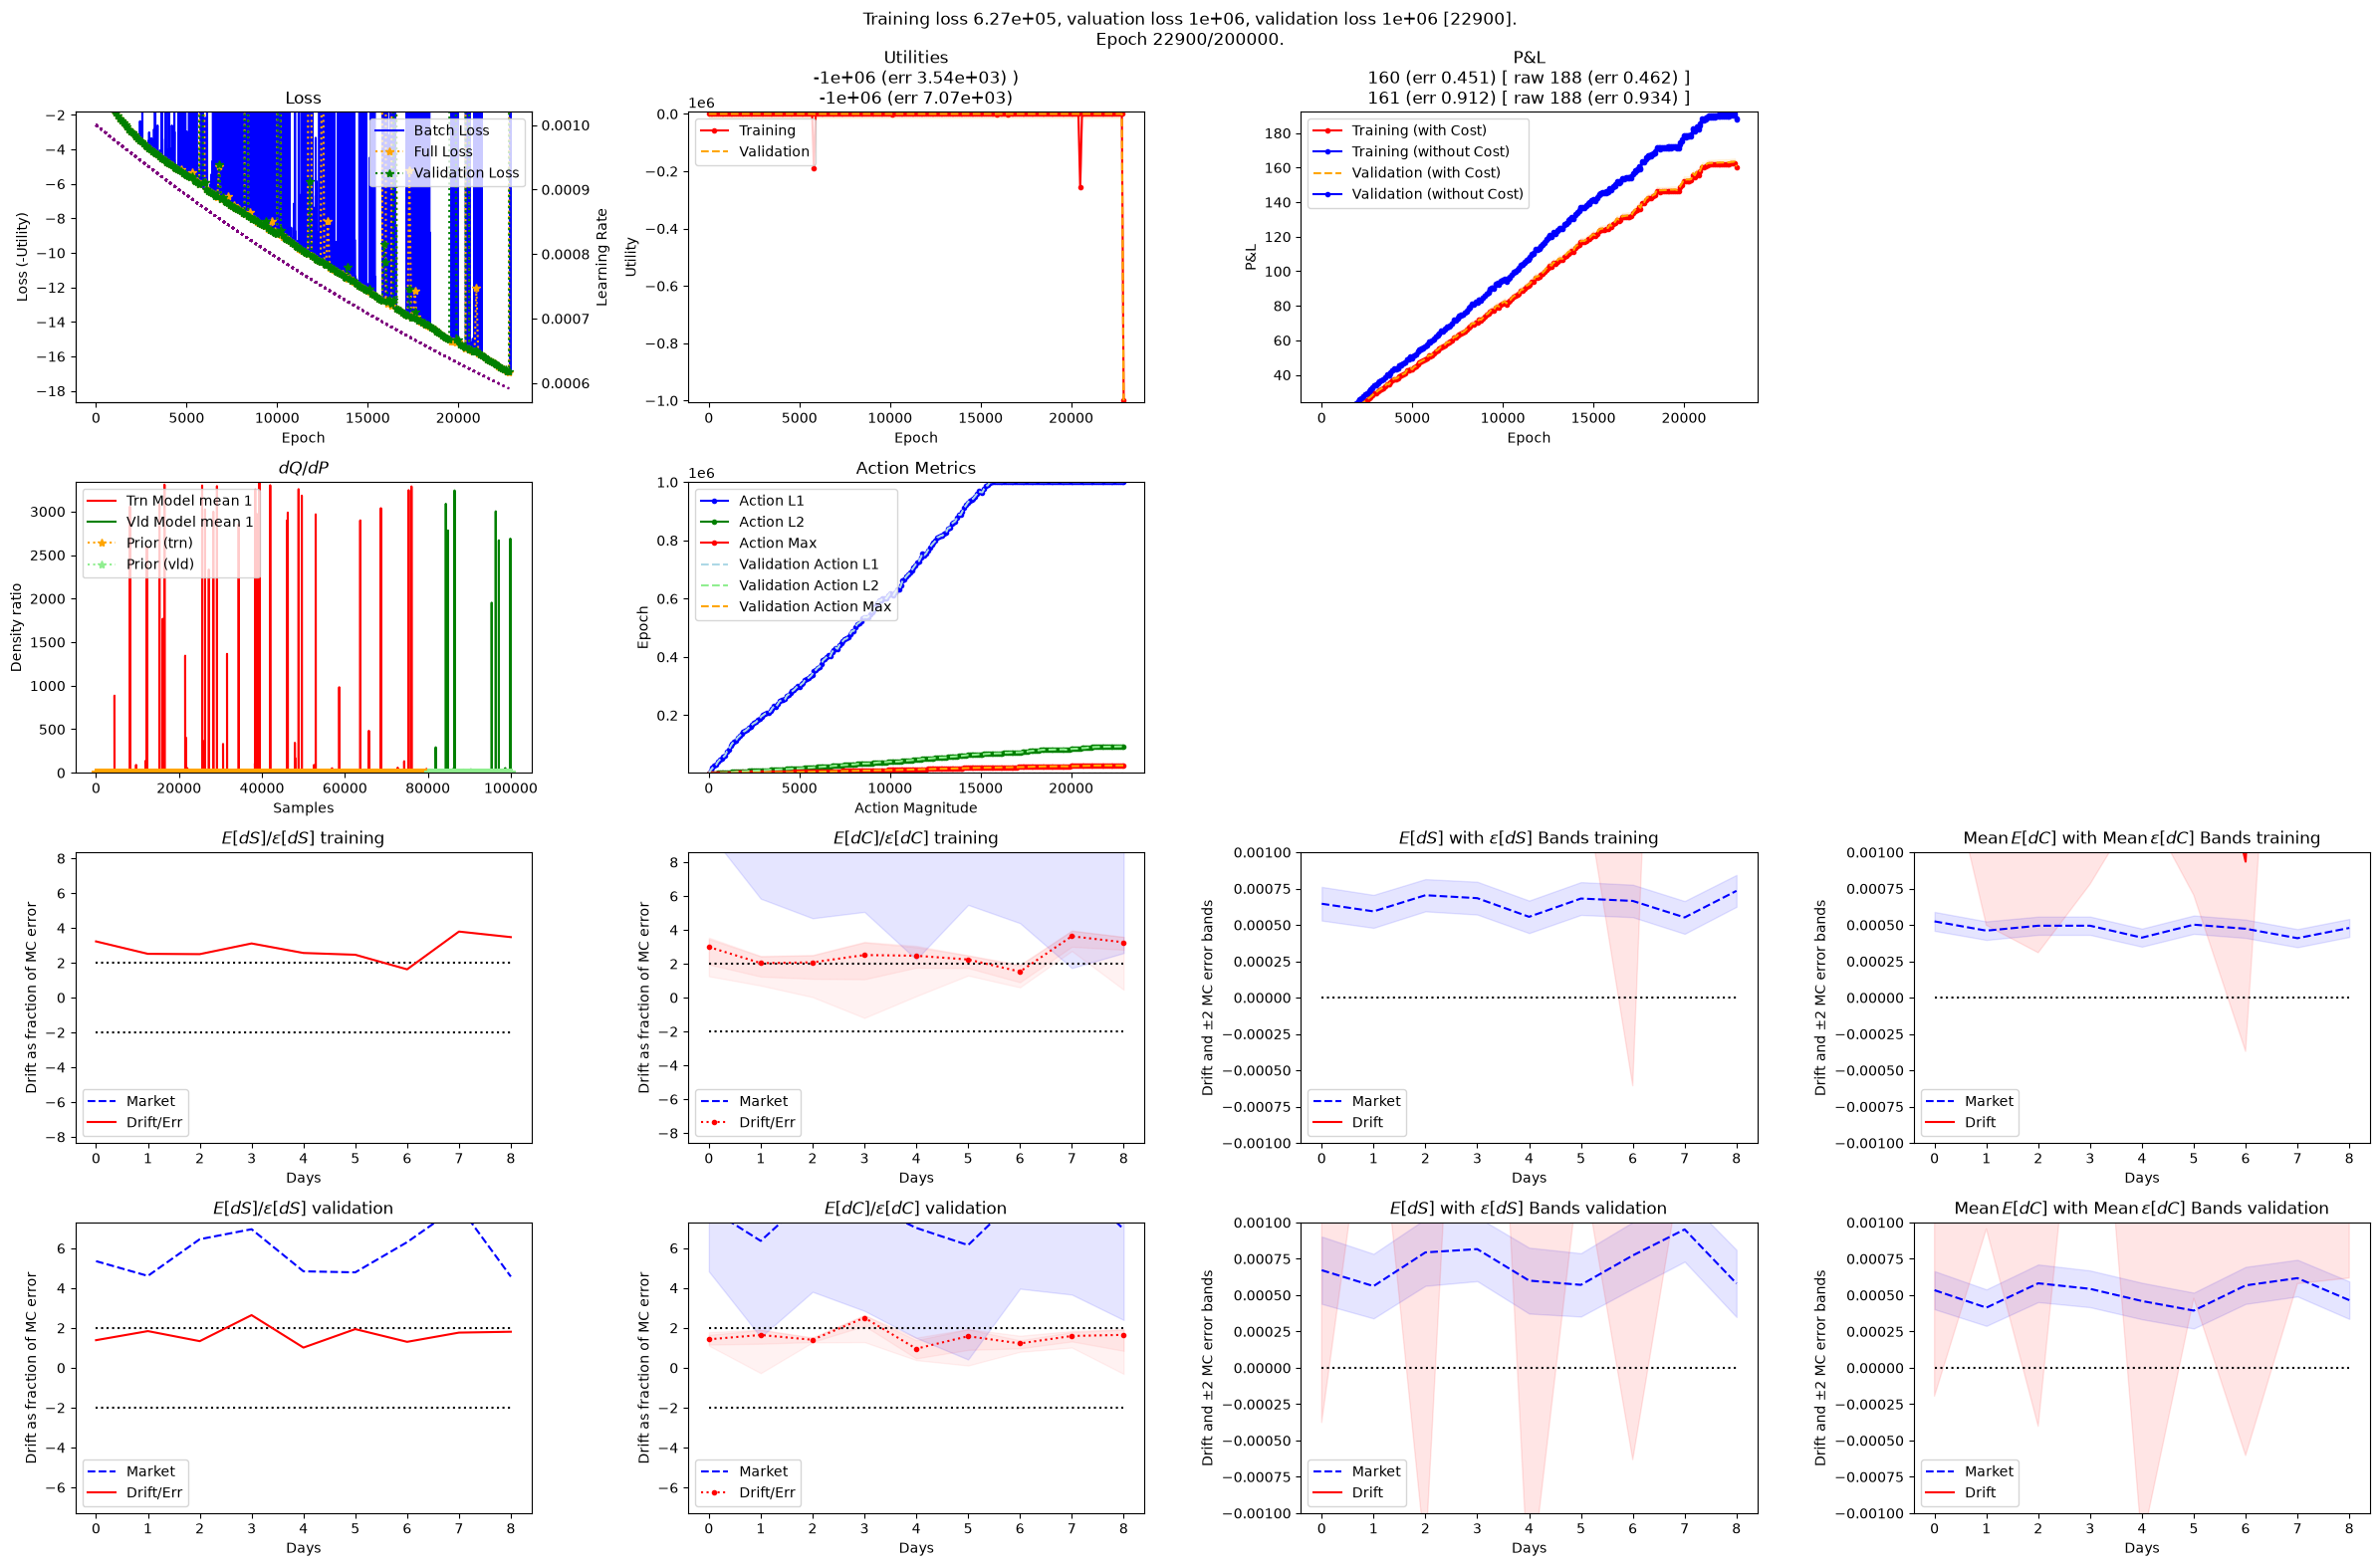

00: Training drn-pf-std_cost-powerexp-batch@dysanosV2 0.1 with epochs=200000,lr=0.001->1e-05,wdec=0,bsize=10000,vbsize=all,pcnt_val=0.20,compile=True,epoch_interval=100,time_interval=120.0s on Env(prec=32,device=cuda,debug=False):
01:   Epoch 22900/200000: training loss: 6.27e+05, valuation loss: 2.789e+09, validation loss: 2.894e+09; lr 0.0005902. So far this took 22:43. [Check point saved]

In [ ]:
from quantdata.dysanos.grid.torch_drift_changeV2 import DRNConfig, _notebook_name, train, TrainConfig, VizDRNConfig, BaseEnvironment, Context
import torch as torch
import numpy as np
from quantdata.torch.ffw import FeedForwardConfig

mdl_config = DRNConfig( 
    label=_notebook_name(),
    group="dysanosV2", 
    user_version="0.1", 
    utility="entropy", 
    lmbda=1.0, 
    delta_hedged=False, 
    cost = 0.00, # 1 bps
    cost_std = 1./np.sqrt( experiment_config.num_samples ),
    use_fixed=True,
    in_config=FeedForwardConfig(
        num_depth = 2,
        num_width = 40,
        activation = "LeakyReLU",
        use_bias = True
    ),
    pf_config=FeedForwardConfig(
        num_depth = 2,
        num_width = 100,
        activation = "LeakyReLU",
        use_bias = True
    ),
)

import gc
model_RN_output = 0
gc.collect()
print(torch.cuda.memory_allocated() / 1024**3, "GiB allocated")
print(torch.cuda.memory_reserved() / 1024**3, "GiB reserved")

def run():
    trn_config = TrainConfig( num_epochs=200_000, 
                              pcnt_validation=0.2,
                              lr=1E-3, final_lr=1E-5, weight_decay=0., batch_size=10_000, compile=True, epoch_interval=100 )
    viz_config = VizDRNConfig()
    model_RN   = train(
                    ex.universe,
                    ref_dQdP=ex.dQdP_dS,
                    mdl_config=mdl_config, 
                    trn_config=trn_config, 
                    viz_config=viz_config, restart=False, just_load="no",
                    env=BaseEnvironment(debug=False), verbose=Context.all )
    gc.collect()
    return model_RN

model_RN_output = run()
